In [ ]:
import requests
import pandas as pd
from getpass import getpass

CHANNEL_ID = 3535830

# Canal privado: pegá la Read API Key (la de LECTURA). Canal público: dejala vacía y apretá Enter.
READ_API_KEY = getpass("Read API Key (Enter si el canal es público): ").strip()

url = f"https://api.thingspeak.com/channels/{CHANNEL_ID}/feeds.json"
parametros = {"results": 8000}        # 8000 es el máximo de registros que entrega ThingSpeak por pedido
if READ_API_KEY:
    parametros["api_key"] = READ_API_KEY

respuesta = requests.get(url, params=parametros, timeout=30)
print("Código de respuesta:", respuesta.status_code)   # 200 = todo bien

if respuesta.status_code != 200:
    raise RuntimeError("No se pudo descargar. Si el canal es privado, revisá la Read API Key.")

datos = respuesta.json()                 # la respuesta viene en formato JSON
print("Canal:", datos["channel"]["name"])

df = pd.DataFrame(datos["feeds"])        # los registros pasan a una tabla de pandas
print("Registros descargados:", len(df))
df.head()

Read API Key (Enter si el canal es público): ··········
Código de respuesta: 200
Canal: BAKERY PASS
Registros descargados: 394


,created_at,entry_id,field1,field2,field3,field4,field5,field6,field7
0,2026-10-28T23:07:19Z,1,0,0,0,0,0,0,0
1,2026-10-28T23:08:09Z,2,0,0,0,0,0,0,0
2,2026-10-28T23:08:25Z,3,0,0,0,0,0,0,1
3,2026-10-28T23:08:41Z,4,0,0,0,0,0,0,4
4,2026-10-28T23:08:57Z,5,0,0,0,0,0,0,5


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 394 entries, 0 to 393
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   created_at  394 non-null    object
 1   entry_id    394 non-null    int64 
 2   field1      394 non-null    object
 3   field2      394 non-null    object
 4   field3      394 non-null    object
 5   field4      394 non-null    object
 6   field5      394 non-null    object
 7   field6      394 non-null    object
 8   field7      394 non-null    object
dtypes: int64(1), object(8)
memory usage: 27.8+ KB


In [ ]:
print(df.isna().sum())

created_at    0
entry_id      0
field1        0
field2        0
field3        0
field4        0
field5        0
field6        0
field7        0
dtype: int64


In [ ]:
# 2) Cambiar los nombres field por el nombre del dato que manda el Arduino
df = df.rename(columns={
    "field1": "personasDentro",
    "field2": "totalEntradas",
    "field3": "totalSalidas",
    "field4": "estadoAlarma",
    "field5": "estadoMovimiento",
    "field6": "totalAlarmas",
    "field7": "totalMovimientos"})

In [ ]:
# 3) Borrar columnas totalmente vacías (si ThingSpeak las trae)
df = df.drop(columns=["latitude", "longitude", "elevation", "status"], errors="ignore")

In [ ]:
# 4) Conversión de tipos: los datos llegan como texto, se pasan a número
datos = ["personasDentro", "totalEntradas", "totalSalidas", "estadoAlarma",
         "estadoMovimiento", "totalAlarmas", "totalMovimientos"]
df[datos] = df[datos].apply(pd.to_numeric, errors="coerce")

In [ ]:
# 5) Tratamiento de nulos: sin los datos principales se borra la fila; en el resto se pone 0
df = df.dropna(subset=["personasDentro", "totalEntradas", "totalSalidas"])
df[datos] = df[datos].fillna(0).astype(int)

In [ ]:
# 6) Timestamp: de texto a fecha y hora, en horario de Argentina
df["created_at"] = pd.to_datetime(df["created_at"], utc=True).dt.tz_convert("America/Argentina/Buenos_Aires")
df = df.sort_values("created_at").reset_index(drop=True)

print("\nNulos después de limpiar:", int(df.isna().sum().sum()))
df.info()
df.head()


Nulos después de limpiar: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 394 entries, 0 to 393
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype                                         
---  ------            --------------  -----                                         
 0   created_at        394 non-null    datetime64[ns, America/Argentina/Buenos_Aires]
 1   entry_id          394 non-null    int64                                         
 2   personasDentro    394 non-null    int64                                         
 3   totalEntradas     394 non-null    int64                                         
 4   totalSalidas      394 non-null    int64                                         
 5   estadoAlarma      394 non-null    int64                                         
 6   estadoMovimiento  394 non-null    int64                                         
 7   totalAlarmas      394 non-null    int64                                         
 8   to

,created_at,entry_id,personasDentro,totalEntradas,totalSalidas,estadoAlarma,estadoMovimiento,totalAlarmas,totalMovimientos
0,2026-10-28 20:07:19-03:00,1,0,0,0,0,0,0,0
1,2026-10-28 20:08:09-03:00,2,0,0,0,0,0,0,0
2,2026-10-28 20:08:25-03:00,3,0,0,0,0,0,0,1
3,2026-10-28 20:08:41-03:00,4,0,0,0,0,0,0,4
4,2026-10-28 20:08:57-03:00,5,0,0,0,0,0,0,5


In [ ]:
# Estadísticas principales de cada columna de datos
columnas = ["personasDentro", "totalEntradas", "totalSalidas", "estadoAlarma",
            "estadoMovimiento", "totalAlarmas", "totalMovimientos"]

estadisticas = df[columnas].agg(["mean", "median", "std", "min", "max"]).round(2)
estadisticas

,personasDentro,totalEntradas,totalSalidas,estadoAlarma,estadoMovimiento,totalAlarmas,totalMovimientos
mean,9.28,42.38,33.09,0.59,0.22,4.16,98.57
median,6.00,34.00,21.50,1.00,0.00,3.00,76.00
std,10.33,34.77,35.51,0.49,0.41,3.78,80.42
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00
max,52.00,126.00,126.00,1.00,1.00,14.00,281.00


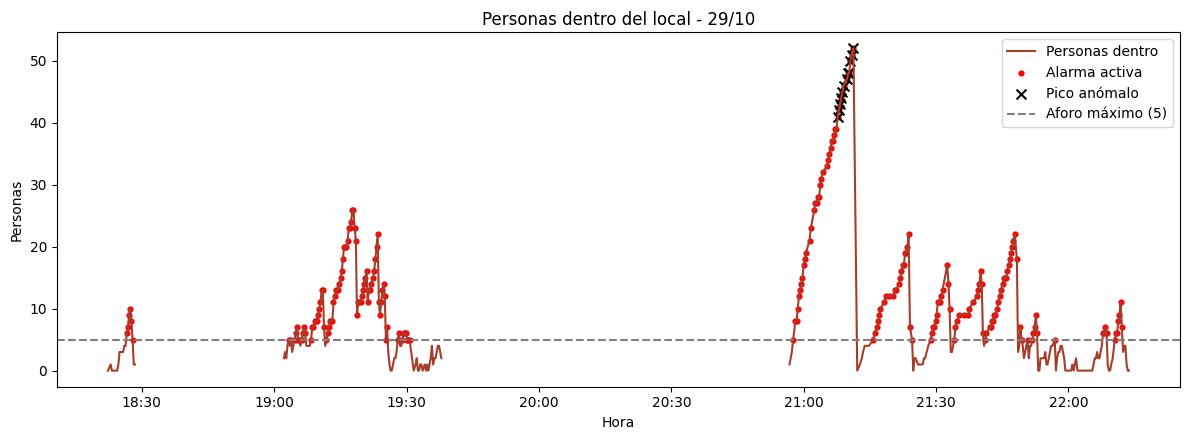

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

aforo = df[df["estadoAlarma"] == 1]["personasDentro"].min()                       # personas con las que sonó la alarma
limite_pico = df["personasDentro"].mean() + 3 * df["personasDentro"].std()       # sobre este valor es un pico anómalo
dia = df[df["created_at"].dt.date == df["created_at"].dt.date.value_counts().idxmax()].copy()   # día con más datos

# Si pasaron más de 5 minutos sin datos, se corta la línea para no unir puntos lejanos
dia.loc[dia["created_at"].diff() > pd.Timedelta("5min"), ["personasDentro", "totalEntradas", "totalSalidas"]] = None
hora_local = mdates.DateFormatter("%H:%M", tz=df["created_at"].dt.tz)

# GRÁFICO 1: serie de tiempo de personas dentro, con alarma, aforo y picos
plt.figure(figsize=(12, 4.5))
plt.plot(dia["created_at"], dia["personasDentro"], color="#a63d2a", label="Personas dentro")
alarma = dia[dia["estadoAlarma"] == 1]
plt.scatter(alarma["created_at"], alarma["personasDentro"], color="red", s=12, label="Alarma activa")
picos_dia = dia[dia["personasDentro"] > limite_pico]
plt.scatter(picos_dia["created_at"], picos_dia["personasDentro"], color="black", marker="x", s=50, label="Pico anómalo")
plt.axhline(aforo, color="gray", linestyle="--", label=f"Aforo máximo ({aforo})")
plt.gca().xaxis.set_major_formatter(hora_local)
plt.title("Personas dentro del local - " + dia["created_at"].iloc[0].strftime("%d/%m"))
plt.xlabel("Hora")
plt.ylabel("Personas")
plt.legend()
plt.tight_layout()
plt.show()

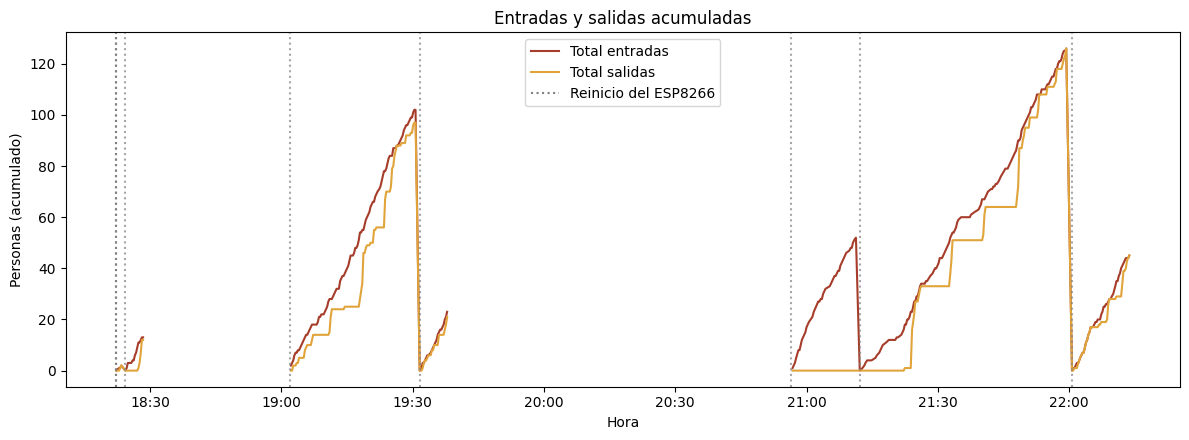

In [ ]:
# GRÁFICO 2: contadores acumulados. Cuando bajan a 0, el ESP8266 se reinició
reinicios = df[df["totalEntradas"].diff() < 0]
reinicios_dia = reinicios[reinicios["created_at"].dt.date == dia["created_at"].dt.date.iloc[0]]

plt.figure(figsize=(12, 4.5))
plt.plot(dia["created_at"], dia["totalEntradas"], color="#a63d2a", label="Total entradas")
plt.plot(dia["created_at"], dia["totalSalidas"], color="#e0a43a", label="Total salidas")
for momento in reinicios_dia["created_at"]:
    plt.axvline(momento, color="gray", linestyle=":", alpha=0.7)
plt.axvline(reinicios_dia["created_at"].iloc[0], color="gray", linestyle=":", label="Reinicio del ESP8266")
plt.gca().xaxis.set_major_formatter(hora_local)
plt.title("Entradas y salidas acumuladas")
plt.xlabel("Hora")
plt.ylabel("Personas (acumulado)")
plt.legend()
plt.tight_layout()
plt.show()

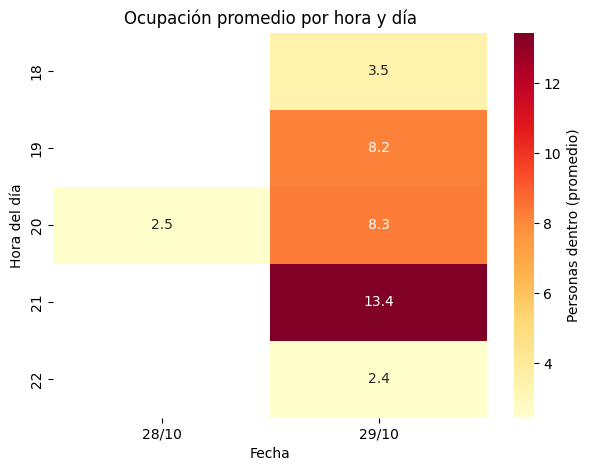

In [ ]:
# MAPA DE CALOR 1: promedio de personas dentro, por hora y por día
hora = df["created_at"].dt.hour.rename("hora")
fecha = df["created_at"].dt.strftime("%d/%m").rename("fecha")
tabla = df.pivot_table(index=hora, columns=fecha, values="personasDentro", aggfunc="mean")

plt.figure(figsize=(7, 5))
sns.heatmap(tabla, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Personas dentro (promedio)"})
plt.title("Ocupación promedio por hora y día")
plt.xlabel("Fecha")
plt.ylabel("Hora del día")
plt.show()

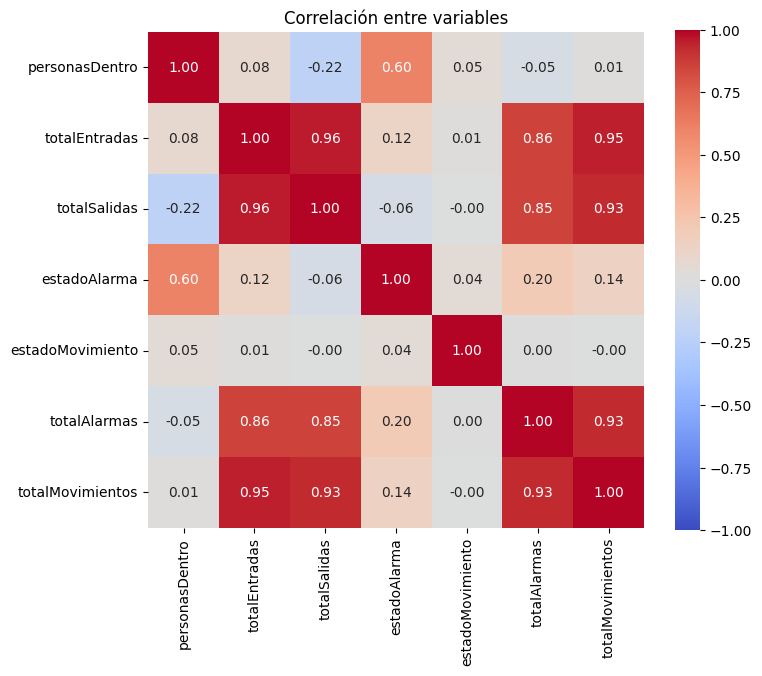

In [ ]:
# MAPA DE CALOR 2: correlación entre las columnas de datos
correlacion = df.drop(columns=["created_at", "entry_id"]).corr()

plt.figure(figsize=(8, 6.5))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlación entre variables")
plt.show()

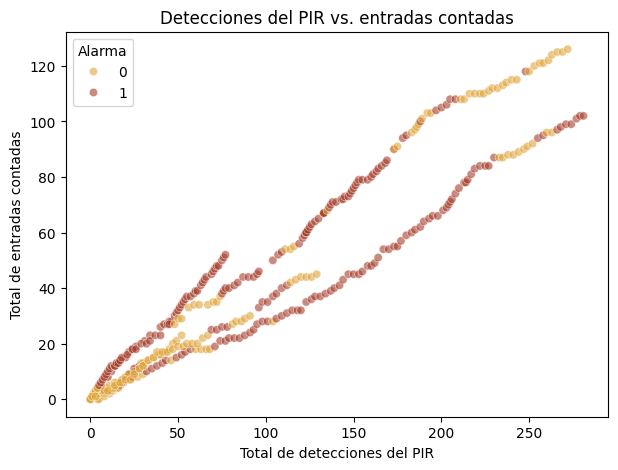

In [ ]:
# DIAGRAMA DE DISPERSIÓN: detecciones del PIR vs. entradas contadas
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="totalMovimientos", y="totalEntradas", hue="estadoAlarma", palette={0: "#e0a43a", 1: "#a63d2a"}, alpha=0.6)
plt.title("Detecciones del PIR vs. entradas contadas")
plt.xlabel("Total de detecciones del PIR")
plt.ylabel("Total de entradas contadas")
plt.legend(title="Alarma")
plt.show()

In [ ]:
# ANOMALÍAS: tablas con los casos encontrados
# 1) Picos de ocupación (más de 3 desviaciones estándar sobre la media)
picos = df[df["personasDentro"] > limite_pico]
print("Picos de ocupación (más de", round(limite_pico), "personas):", len(picos))
display(picos[["created_at", "personasDentro"]].head())

# 2) Reinicios del ESP8266 (el contador baja en vez de subir)
print("\nReinicios del ESP8266:", len(reinicios))
display(reinicios[["created_at", "totalEntradas"]])

# 3) Huecos: más de 60 segundos sin recibir datos
segundos = df["created_at"].diff().dt.total_seconds()
huecos = pd.DataFrame({"created_at": df["created_at"][segundos > 60], "segundos_sin_datos": segundos[segundos > 60]})
print("\nHuecos entre lecturas:", len(huecos))
display(huecos)

Picos de ocupación (más de 40 personas): 12


,created_at,personasDentro
200,2026-10-29 21:07:42-03:00,41
201,2026-10-29 21:07:58-03:00,42
202,2026-10-29 21:08:14-03:00,43
203,2026-10-29 21:08:30-03:00,44
204,2026-10-29 21:08:46-03:00,45



Reinicios del ESP8266: 7


,created_at,totalEntradas
15,2026-10-29 18:22:19-03:00,0
19,2026-10-29 18:24:23-03:00,0
35,2026-10-29 19:01:56-03:00,2
143,2026-10-29 19:31:37-03:00,0
166,2026-10-29 20:56:26-03:00,0
212,2026-10-29 21:12:08-03:00,0
347,2026-10-29 22:00:37-03:00,0



Huecos entre lecturas: 5


,created_at,segundos_sin_datos
15,2026-10-29 18:22:19-03:00,79841.0
35,2026-10-29 19:01:56-03:00,2010.0
166,2026-10-29 20:56:26-03:00,4713.0
262,2026-10-29 21:32:32-03:00,63.0
347,2026-10-29 22:00:37-03:00,79.0


In [ ]:
from google.colab import files
df.to_csv("/content/datosLimpios.csv", index=False, encoding="utf-8-sig")
print("Archivo guardado: datosLimpios.csv")

Archivo guardado: datosLimpios.csv


In [ ]:
files.download("/content/datosLimpios.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>